# Multispecies training

This notebook trains one narrow ResNet9 patch encoder for two synthetic species, newts
and frogs, under complete pooling. Its backbone is shared by both species and feeds one
species-specific head per species. Multispecies support is experimental.

In [1]:
import tempfile
from pathlib import Path

import coordax as cx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from ilg_toolkit import (
    load_model,
    MLPELoss,
    PairwiseObservations,
    RegionBatch,
    ResistanceSolverConfig,
    save_model,
    TargetSpec,
    train,
    TrainingConfig,
)
from ilg_toolkit.models import LogLinearConductance, ResNet9Conductance
from IPython.display import display, Markdown
from scipy.ndimage import gaussian_filter


jax.config.update("jax_enable_x64", True)

SPECIES = ("newt", "frog")
FEATURES = ("canopy", "moisture")
CELLS = 48  # Raster side length in cells.
PATCH_SIZE = 8  # Groups 8x8 cells into one vertex: a 6x6 conductance grid graph.
UNITS = 12  # Sampling units per species and region, each at its own vertex.
target = TargetSpec("genetic dissimilarity", units="index")
solver_config = ResistanceSolverConfig(solver="cudss" if jax.default_backend() == "gpu" else "cg")

## Simulate two regions

The valley and the upland each have two landscape features, canopy and moisture, on a
48 × 48 raster. Both species are sampled in the valley; only newts are sampled in the
upland. A log-linear patch encoder with the same species names simulates ecological
distances: newts move more easily under canopy, frogs over moist ground. Genetic
dissimilarities are an affine function of these distances with 2% multiplicative noise.

Each region batch carries a labeled feature axis naming its features and labels each
sampling unit with its species.

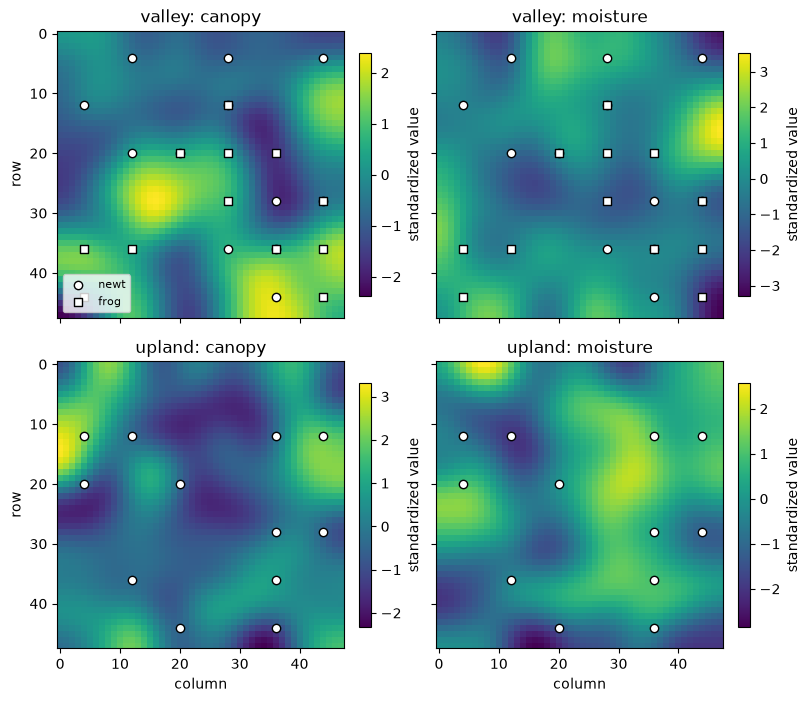

In [2]:
simulator = eqx.tree_at(
    lambda model: model.coefficients,
    LogLinearConductance(2, species=SPECIES, patch_size=PATCH_SIZE, solver_config=solver_config),
    jnp.array([[2.0, 0.0], [0.0, 2.0]]),  # One row of feature coefficients per species.
)


def simulate(name, present, seed):
    rng = np.random.default_rng(seed)
    values = np.stack(
        [gaussian_filter(rng.normal(size=(CELLS, CELLS)), 4) for _ in FEATURES], axis=-1
    )
    values = (values - values.mean((0, 1))) / values.std((0, 1))
    features = cx.field(
        values.astype(np.float32),
        "row",
        "column",
        cx.LabeledAxis("feature", np.array(FEATURES)),
    )
    vertices = CELLS // PATCH_SIZE
    ids, positions, labels = [], [], []
    for species in present:
        chosen = rng.choice(vertices**2, UNITS, replace=False)
        positions += [
            [
                vertex // vertices * PATCH_SIZE + PATCH_SIZE // 2,
                vertex % vertices * PATCH_SIZE + PATCH_SIZE // 2,
            ]
            for vertex in chosen
        ]
        ids += [f"{species}-{index}" for index in range(1, UNITS + 1)]
        labels += [species] * UNITS
    region = RegionBatch(name, features, tuple(ids), np.array(positions), species=tuple(labels))
    distances = simulator.predict(region, {species: None for species in present})
    observations = tuple(
        PairwiseObservations.from_pairs(
            distances[species].pairs,
            (0.2 + 0.1 * np.asarray(distances[species].values))
            * np.exp(rng.normal(0, 0.02, len(distances[species].pairs))),
            target=target,
            species=species,
        )
        for species in present
    )
    return region, observations


valley, valley_observations = simulate("valley", SPECIES, 1)
upland, upland_observations = simulate("upland", ("newt",), 2)
regions = (valley, upland)
observations = (valley_observations, upland_observations)

markers = {"newt": "o", "frog": "s"}
figure, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True, layout="constrained")
for row, region in zip(axes, regions, strict=True):
    for axis, feature in zip(row, FEATURES, strict=True):
        image = axis.imshow(region.features.data[..., FEATURES.index(feature)], cmap="viridis")
        for species in markers:
            units = np.asarray(region.species) == species
            if units.any():
                rows, columns = np.asarray(region.grid_positions)[units].T
                axis.scatter(
                    columns,
                    rows,
                    marker=markers[species],
                    c="white",
                    edgecolors="black",
                    label=species,
                )
        axis.set(title=f"{region.name}: {feature}", xlabel="column", ylabel="row")
        axis.label_outer()
        figure.colorbar(image, ax=axis, shrink=0.8, label="standardized value")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.show()

## Train the patch encoder

`ResNet9Conductance` with `species=SPECIES` builds a backbone of three convolutional
stages and two residual blocks, shared by both species, and one species-specific head per
species: a linear map with softplus to the conductance of each vertex. The channel widths
`(8, 16, 32)` keep the patch encoder narrow. Its resistance solver, `solver_config`, is the
NVIDIA CUDA Direct Sparse Solver (cuDSS) on a GPU and conjugate gradient elsewhere.

`train` reads the species names from the distance model. Each species has equal influence,
and each region has equal influence within a species. The maximum-likelihood population
effects (MLPE) loss fits one MLPE calibration per region–species group, and the selected
model's MLPE calibration head holds them.

In [3]:
distance_model = ResNet9Conductance(
    len(FEATURES),
    species=SPECIES,
    patch_size=PATCH_SIZE,
    channels=(8, 16, 32),
    solver_config=solver_config,
    key=jax.random.key(0),
)
state = train(
    regions,
    observations,
    distance_model=distance_model,
    config=TrainingConfig(loss=MLPELoss(), steps=300, eval_every=50, optimizer=optax.adam(1e-2)),
)
model = state.selected_model
print("Species:", model.species)
for record in (state.history[0], state.history[-1]):
    losses = ", ".join(f"{name} {value:.3f}" for name, value in record.training_by_species.items())
    print(f"MLPE loss at step {record.step}: {losses}")

rows = [
    "| Region | Species | Slope | Population-effect variance | Residual variance |",
    "| --- | --- | ---: | ---: | ---: |",
]
for region, region_observations in zip(regions, observations, strict=True):
    for species_observations in region_observations:
        name = species_observations.species
        calibration = model.calibration_head.for_region(region.name, name)
        rows.append(
            f"| {region.name} | {name} | {calibration.slope:.4f} | "
            f"{calibration.unit_variance:.2e} | {calibration.residual_variance:.2e} |"
        )
display(Markdown("\n".join(rows)))

Species: ('newt', 'frog')
MLPE loss at step 0: newt -1.751, frog -1.831
MLPE loss at step 300: newt -3.297, frog -3.322


| Region | Species | Slope | Population-effect variance | Residual variance |
| --- | --- | ---: | ---: | ---: |
| valley | newt | 0.0897 | 1.07e-04 | 2.12e-04 |
| valley | frog | 0.0590 | 5.01e-05 | 1.07e-04 |
| upland | newt | 0.0500 | 3.06e-05 | 7.40e-05 |

## Predict by species

`predict` takes a query mapping each species to its pairs; `None` requests all of a
species' pairs. A mapping query returns a mapping of predictions by species. Here each
species' query lists its observed pairs, so predictions align with the observations.

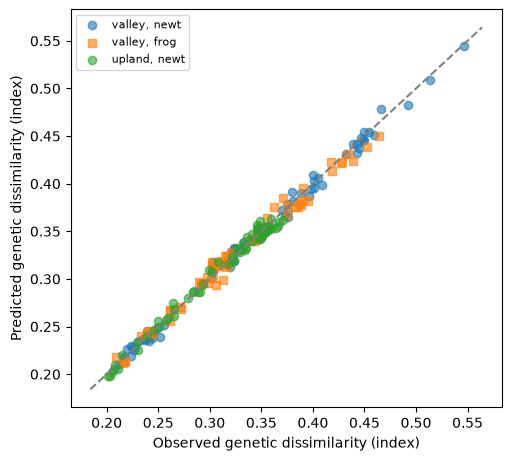

Frog pairs: (('frog-1', 'frog-2'), ('frog-3', 'frog-4'))
Frog predictions: [0.4384 0.3154]
Newt pairs predicted: 66


In [4]:
figure, axis = plt.subplots(figsize=(5, 4.5), layout="constrained")
for region, region_observations in zip(regions, observations, strict=True):
    query = {item.species: item.observed_pairs for item in region_observations}
    predictions = model.predict(region, query)
    for item in region_observations:
        axis.scatter(
            item.observed_values,
            predictions[item.species].values,
            marker=markers[item.species],
            alpha=0.6,
            label=f"{region.name}, {item.species}",
        )
limits = axis.get_xlim()
axis.plot(limits, limits, linestyle="--", color="gray")
axis.set(
    xlabel="Observed genetic dissimilarity (index)",
    ylabel="Predicted genetic dissimilarity (index)",
)
axis.legend(fontsize=8)
plt.show()

predictions = model.predict(
    valley, {"frog": [("frog-1", "frog-2"), ("frog-3", "frog-4")], "newt": None}
)
print("Frog pairs:", predictions["frog"].pairs)
print("Frog predictions:", np.round(np.asarray(predictions["frog"].values), 4))
print("Newt pairs predicted:", len(predictions["newt"].pairs))

## Conductance surfaces

`conductance_surface` returns one species' learned conductance surface by name as a
coordax field with `row` and `column` dimensions; `.data` holds its values. MLPE
standardizes ecological distances, so the maps show log₁₀ conductance relative to its mean
over the region, for the simulated and the learned conductance surfaces.

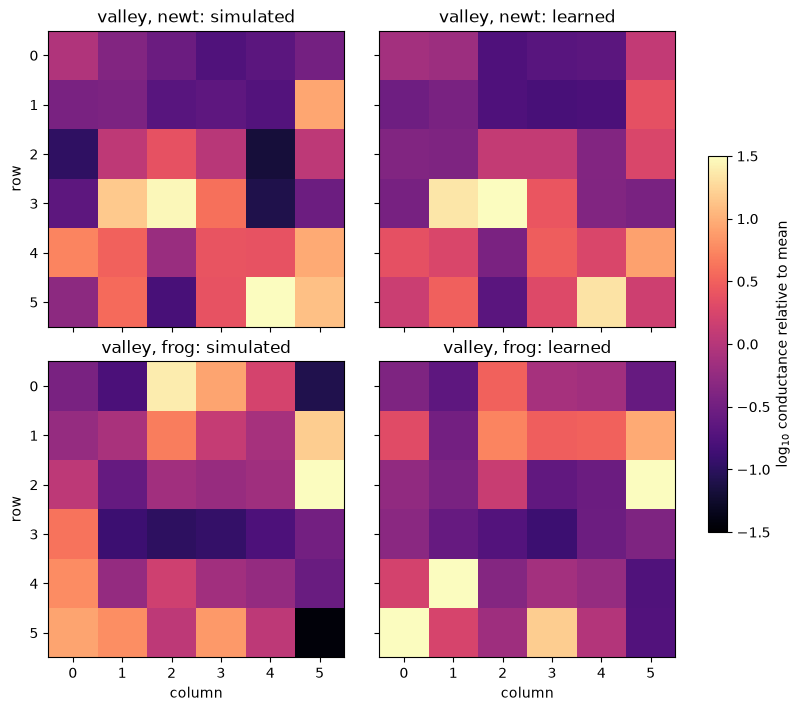

In [5]:
figure, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True, layout="constrained")
for row, species in zip(axes, SPECIES, strict=True):
    surfaces = {
        "simulated": simulator.conductance_surface(valley, species),
        "learned": model.distance_model.conductance_surface(valley, species),
    }
    for axis, (kind, surface) in zip(row, surfaces.items(), strict=True):
        values = np.log10(np.asarray(surface.data))
        image = axis.imshow(values - values.mean(), cmap="magma", vmin=-1.5, vmax=1.5)
        axis.set(title=f"valley, {species}: {kind}", xlabel="column", ylabel="row")
        axis.label_outer()
figure.colorbar(image, ax=axes, shrink=0.6, label="log$_{10}$ conductance relative to mean")
plt.show()

## Save and reload

`save_model` writes the distance model with its species names and the calibration head to
one file. `load_model` restores them into a template with the same architecture and
species, replacing the template's parameter values and resistance solver. The reloaded
model equals the trained model, and its predictions match to a relative tolerance of 1e-6.

In [6]:
query = {"newt": None, "frog": None}
with tempfile.TemporaryDirectory() as directory:
    path = Path(directory) / "multispecies.eqx"
    save_model(path, model)
    template = ResNet9Conductance(
        len(FEATURES),
        species=SPECIES,
        patch_size=PATCH_SIZE,
        channels=(8, 16, 32),
        key=jax.random.key(1),
    )
    restored = load_model(path, distance_model=template)
print("Species:", restored.species)
print("Reloaded model equals the trained model:", bool(eqx.tree_equal(restored, model)))
original = model.predict(valley, query)
reloaded = restored.predict(valley, query)
for species in SPECIES:
    match = np.allclose(reloaded[species].values, original[species].values, rtol=1e-6, atol=0)
    print(f"{species} predictions match: {match}")

Species: ('newt', 'frog')


Reloaded model equals the trained model: True
newt predictions match: True
frog predictions match: True
